In [ ]:
#Import Libraries
# Install dependencies (if not already)
!pip install pandas numpy tensorflow scikit-learn matplotlib seaborn

# Imports

import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, RobustScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# CHIRPS data
chirps = pd.read_csv('CHIRPS2025.csv')  # Columns: lon, lat, rainfall, date
chirps['date'] = pd.to_datetime(chirps['date'], format='%Y%m%d')

# NASA POWER data
nasa = pd.read_csv('NASA2025.csv')  # Columns: date, latitude, longitude, T2M, RH2M, WS2M, ALLSKY_SFC_SW_DWN
nasa['date'] = pd.to_datetime(nasa['date'], format='%d/%m/%Y')


In [ ]:
print(chirps.head())
print(nasa.head())

          lon       lat  rainfall       date
0  110.775004  0.724999       NaN 2025-01-01
1  110.825004  0.724999       NaN 2025-01-01
2  110.875004  0.724999       NaN 2025-01-01
3  110.925004  0.724999       NaN 2025-01-01
4  110.975004  0.724999       NaN 2025-01-01
        date  latitude   longitude    T2M   RH2M  WS2M  ALLSKY_SFC_SW_DWN
0 2025-04-30 -0.043607  113.434479  24.36  89.37  0.19             5.0191
1 2025-04-30 -0.043607  113.484479  24.51  90.36  0.12             5.0191
2 2025-04-30 -0.043607  113.534479  24.51  90.36  0.12             5.0191
3 2025-04-30 -0.043607  113.584479  24.51  90.36  0.12             5.0191
4 2025-04-30 -0.043607  113.634479  24.51  90.36  0.12             5.0191


In [ ]:
#Sort and merge the datasets

#Align lat/lon grids
# Round latitude and longitude to 2 decimal places (0.05° grid)
nasa['latitude'] = (nasa['latitude'] / 0.05).round() * 0.05
nasa['longitude'] = (nasa['longitude'] / 0.05).round() * 0.05

chirps['lat'] = (chirps['lat'] / 0.05).round() * 0.05
chirps['lon'] = (chirps['lon'] / 0.05).round() * 0.05


# Sort datasets
nasa = nasa.sort_values(by=['latitude', 'longitude', 'date']).reset_index(drop=True)
chirps = chirps.sort_values(by=['lat', 'lon', 'date']).reset_index(drop=True)

# Merge on nearest lat/lon and date
merged = pd.merge(chirps, nasa, left_on=['lat', 'lon', 'date'], right_on=['latitude', 'longitude', 'date'], how='inner')

# Drop duplicate lat/lon columns
merged = merged.drop(columns=['latitude', 'longitude'])

In [ ]:
print(merged.isna().sum())

lon                     0
lat                     0
rainfall             1071
date                    0
T2M                     0
RH2M                    0
WS2M                    0
ALLSKY_SFC_SW_DWN       0
dtype: int64


In [ ]:
merged = merged.dropna()

In [ ]:
print(merged.isna().sum())

lon                  0
lat                  0
rainfall             0
date                 0
T2M                  0
RH2M                 0
WS2M                 0
ALLSKY_SFC_SW_DWN    0
dtype: int64


In [ ]:
print(merged.head())

     lon  lat   rainfall       date    T2M   RH2M  WS2M  ALLSKY_SFC_SW_DWN
0  113.3 -0.4   7.966590 2025-01-02  24.60  92.25  0.21             4.1875
1  113.3 -0.4  31.866362 2025-01-03  24.32  93.36  0.17             4.2528
2  113.3 -0.4   0.000000 2025-01-04  24.37  93.18  0.18             5.0107
3  113.3 -0.4   0.000000 2025-01-05  24.68  90.14  0.11             5.6813
4  113.3 -0.4   0.000000 2025-01-06  24.89  91.43  0.16             5.5730


In [ ]:
#Rainfall is highly skewed (many zeros). So Log Transformation
merged['rainfall'] = np.log1p(merged['rainfall'])
print(merged.head())

     lon  lat  rainfall       date    T2M   RH2M  WS2M  ALLSKY_SFC_SW_DWN
0  113.3 -0.4  2.193505 2025-01-02  24.60  92.25  0.21             4.1875
1  113.3 -0.4  3.492450 2025-01-03  24.32  93.36  0.17             4.2528
2  113.3 -0.4  0.000000 2025-01-04  24.37  93.18  0.18             5.0107
3  113.3 -0.4  0.000000 2025-01-05  24.68  90.14  0.11             5.6813
4  113.3 -0.4  0.000000 2025-01-06  24.89  91.43  0.16             5.5730


In [ ]:
#Feature scaling

#Using RobustScaler is a good idea because it handles outliers better.
#For features like temperature, wind speed, etc., we can use MinMaxScaler.

# Features and target
features = ['T2M', #2-meter air temperature (°C)
            'RH2M',#2-meter relative humidity (%)
            'WS2M',#2-meter wind speed (m/s)
            'ALLSKY_SFC_SW_DWN' #Surface shortwave radiation (MJ/m²/day)
            ]
target = ['rainfall']

# Scaling features
feature_scaler = MinMaxScaler()
merged[features] = feature_scaler.fit_transform(merged[features])

# Scaling target (rainfall)
target_scaler = RobustScaler()
merged[target] = target_scaler.fit_transform(merged[target])

In [ ]:
#Create sequences for LSTM

sequence_length = 7  # use 7 days to predict next day

X = []
y = []

data_values = merged[features + target].values

for i in range(sequence_length, len(data_values)):
    X.append(data_values[i-sequence_length:i, :-1])  # features for last 7 days
    y.append(data_values[i, -1])  # rainfall of the next day

X, y = np.array(X), np.array(y)

print("X shape:", X.shape)  # (samples, timesteps, features)
print("y shape:", y.shape)  # (samples,)

X shape: (29981, 7, 4)
y shape: (29981,)


In [ ]:
#Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

In [ ]:
#LSTM model
model = Sequential()
model.add(LSTM(64, input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=True))
model.add(Dropout(0.2))
model.add(LSTM(32, return_sequences=False))
model.add(Dropout(0.2))
model.add(Dense(1))  # predicting rainfall

model.compile(optimizer='adam', loss='mse', metrics=['mae'])
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 7, 64)          │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 7, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,113 (117.63 KB)

 Trainable params: 30,113 (117.63 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Train the model
history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/50
600/600 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - loss: 0.7887 - mae: 0.7217 - val_loss: 0.7299 - val_mae: 0.6825
Epoch 2/50
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 0.7567 - mae: 0.7031 - val_loss: 0.7116 - val_mae: 0.6732
Epoch 3/50
600/600 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - loss: 0.7347 - mae: 0.6901 - val_loss: 0.6935 - val_mae: 0.6733
Epoch 4/50
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 0.7142 - mae: 0.6810 - val_loss: 0.6737 - val_mae: 0.6706
Epoch 5/50
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - loss: 0.6941 - mae: 0.6699 - val_loss: 0.6545 - val_mae: 0.6542
Epoch 6/50
600/600 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - loss: 0.6459 - mae: 0.6340 - val_loss: 0.6119 - val_mae: 0.6300
Epoch 7/50
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 0.6322 - mae: 0.6284 - val_loss: 0.5746 - val_mae: 0.6108
Epoch 8/50
600/600 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - loss: 0.5944 - mae: 0.6062 - val_loss: 0.5708 - val_mae: 0.6136
Epoch 9/50
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/

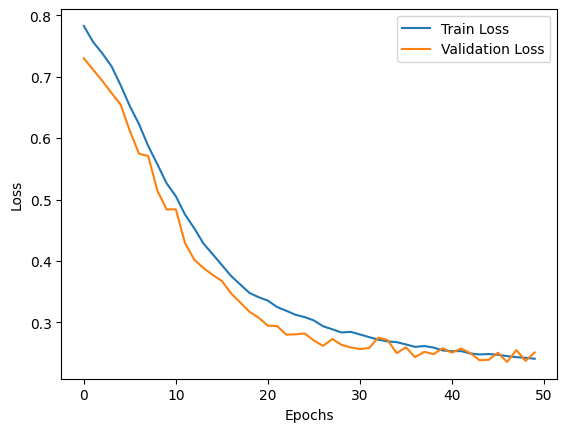

In [ ]:
#Plot training history
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


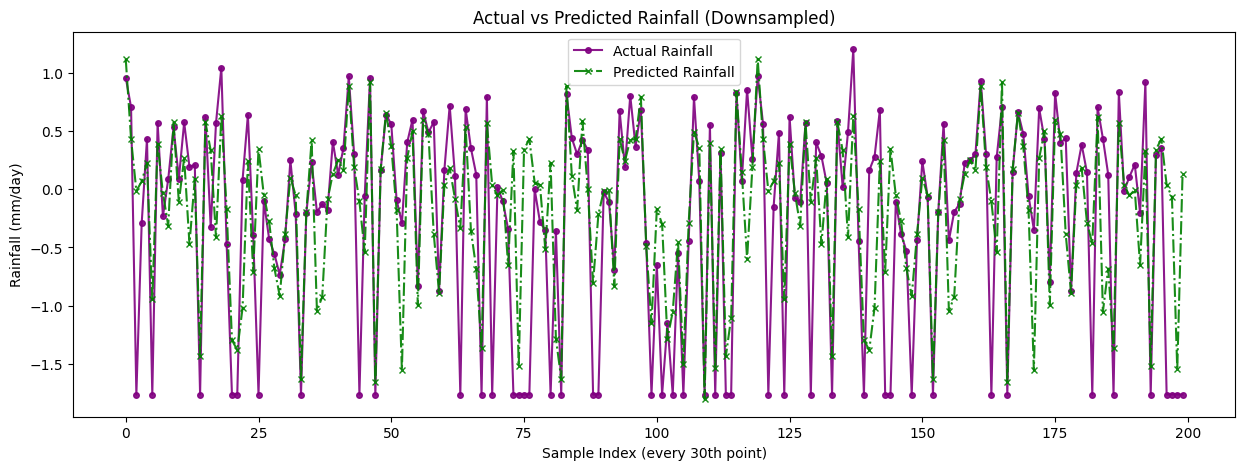

In [ ]:
#Make predictions and inverse transform
y_pred = model.predict(X_test)

# Inverse scale
y_test_inv = target_scaler.inverse_transform(y_test.reshape(-1,1))
y_pred_inv = target_scaler.inverse_transform(y_pred)

# Plot predictions vs actual
step = 30
plt.figure(figsize=(15,5))
plt.plot(y_test_inv[::step], label='Actual Rainfall', color='purple', marker='o', markersize=4, linestyle='-', alpha=0.9)
plt.plot(y_pred_inv[::step], label='Predicted Rainfall', color='green', marker='x', markersize=4, linestyle='-.', alpha=0.9)
plt.title('Actual vs Predicted Rainfall (Downsampled)')
plt.xlabel('Sample Index (every 30th point)')
plt.ylabel('Rainfall (mm/day)')
plt.legend()
plt.show()

In [ ]:
#Correlation between Actual & Predicted Rainfall
corr = np.corrcoef(
    y_test_inv.flatten(),
    y_pred_inv.flatten()
)[0, 1]

print(f"Correlation (Actual vs Predicted): {corr:.4f}")


Correlation (Actual vs Predicted): 0.7065


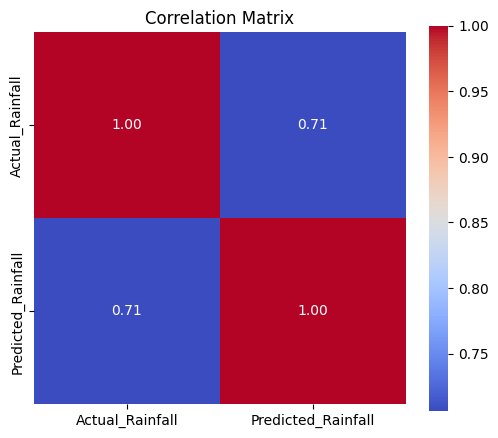

In [ ]:
#Full Correlation Matrix (Features + Rainfall)

corr_df = pd.DataFrame({
    'Actual_Rainfall': y_test_inv.flatten(),
    'Predicted_Rainfall': y_pred_inv.flatten()
})


plt.figure(figsize=(6,5))
sns.heatmap(
    corr_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    square=True
)
plt.title("Correlation Matrix")
plt.show()

In [ ]:
#MAE (Mean Absolute Error)
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(
    y_test_inv.flatten(),
    y_pred_inv.flatten()
)

print(f"MAE: {mae:.3f} mm/day")

#RMSE (Root Mean Squared Error)
from sklearn.metrics import mean_squared_error

rmse = np.sqrt(mean_squared_error(
    y_test_inv.flatten(),
    y_pred_inv.flatten()
))

print(f"RMSE: {rmse:.3f} mm/day")

MAE: 0.427 mm/day
RMSE: 0.650 mm/day


In [ ]:
#MODEL PERFORMANCE SUMMARY TABLE (Recommended)
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

r2 = r2_score(y_test_inv, y_pred_inv)
mae = mean_absolute_error(y_test_inv, y_pred_inv)
rmse = np.sqrt(mean_squared_error(y_test_inv, y_pred_inv))

metrics_df = pd.DataFrame({
    'Metric': ['R²', 'MAE (mm)', 'RMSE (mm)'],
    'Value': [r2, mae, rmse]
})

metrics_df

,Metric,Value
0,R²,0.485009
1,MAE (mm),0.426904
2,RMSE (mm),0.649529


In [ ]:
#Compairing against Climatology
baseline = np.mean(y_test_inv)
ss = 1 - (
    mean_squared_error(y_test_inv, y_pred_inv) /
    mean_squared_error(y_test_inv, np.full_like(y_test_inv, baseline))
)

print(f"Skill Score vs Climatology: {ss:.3f}")

Skill Score vs Climatology: 0.485


### **Optimized Model**

In [ ]:
# CHIRPS data
chirps1 = pd.read_csv('CHIRPS2025.csv')  # Columns: lon, lat, rainfall, date
chirps1['date'] = pd.to_datetime(chirps1['date'], format='%Y%m%d')

# NASA POWER data
nasa1 = pd.read_csv('NASA2025.csv')  # Columns: date, latitude, longitude, T2M, RH2M, WS2M, ALLSKY_SFC_SW_DWN
nasa1['date'] = pd.to_datetime(nasa1['date'], format='%d/%m/%Y')


In [ ]:
#Interpolating Missing
# Interpolate missing rainfall per grid cell
chirps1['rainfall'] = chirps1.groupby(['lat', 'lon'])['rainfall'].transform(lambda x: x.interpolate(method='linear'))

# Fill any remaining NaNs with 0
chirps1['rainfall'] = chirps1['rainfall'].fillna(0)

In [ ]:
#Sort and merge the datasets

#Align lat/lon grids
# Round latitude and longitude to 2 decimal places (0.05° grid)
nasa1['latitude'] = (nasa1['latitude'] / 0.05).round() * 0.05
nasa1['longitude'] = (nasa1['longitude'] / 0.05).round() * 0.05

chirps1['lat'] = (chirps1['lat'] / 0.05).round() * 0.05
chirps1['lon'] = (chirps1['lon'] / 0.05).round() * 0.05


# Sort datasets
nasa1 = nasa1.sort_values(by=['latitude', 'longitude', 'date']).reset_index(drop=True)
chirps1 = chirps1.sort_values(by=['lat', 'lon', 'date']).reset_index(drop=True)

# Merge on nearest lat/lon and date
merged1 = pd.merge(chirps1, nasa1, left_on=['lat', 'lon', 'date'], right_on=['latitude', 'longitude', 'date'], how='inner')


# Drop duplicate lat/lon columns
merged1 = merged1.drop(columns=['latitude', 'longitude'])

In [ ]:
#Feature scaling

#Using RobustScaler is a good idea because it handles outliers better.
#For features like temperature, wind speed, etc., we can use MinMaxScaler.

# Features and target
features1 = ['T2M', #2-meter air temperature (°C)
            'RH2M',#2-meter relative humidity (%)
            'WS2M',#2-meter wind speed (m/s)
            'ALLSKY_SFC_SW_DWN' #Surface shortwave radiation (MJ/m²/day)
            ]
target1 = ['rainfall']

# Scaling features
feature_scaler1 = MinMaxScaler()
merged1[features1] = feature_scaler.fit_transform(merged1[features1])

# Scaling target (rainfall)
target_scaler1 = RobustScaler()
merged1[target1] = target_scaler1.fit_transform(merged1[target1])

In [ ]:
#Create sequences for LSTM

sequence_length = 7  # use 7 days to predict next day

X1 = []
y1 = []

data_values1 = merged1[features1 + target1].values

for i in range(sequence_length, len(data_values1)):
    X1.append(data_values1[i-sequence_length:i, :-1])  # features for last 7 days
    y1.append(data_values1[i, -1])  # rainfall of the next day

X1, y1 = np.array(X1), np.array(y1)

print("X1 shape:", X1.shape)  # (samples, timesteps, features)
print("y1 shape:", y1.shape)  # (samples,)

X1 shape: (31052, 7, 4)
y1 shape: (31052,)


In [ ]:
#Train-test split
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.2, shuffle=False)

In [ ]:
#Optimized LSTM Model
model1 = Sequential()
model1.add(LSTM(128, input_shape=(X1_train.shape[1], X1_train.shape[2]), return_sequences=True))
model1.add(Dropout(0.3))
model1.add(LSTM(64, return_sequences=False))
model1.add(Dropout(0.3))
model1.add(Dense(1))  # predicting rainfall

model1.compile(optimizer='adam', loss='mse', metrics=['mae'])
model1.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_12 (LSTM)                  │ (None, 7, 128)         │        68,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 7, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_13 (LSTM)                  │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 117,569 (459.25 KB)

 Trainable params: 117,569 (459.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Train the Model
history = model1.fit(
    X1_train, y1_train,
    epochs=70,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/70
621/621 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - loss: 0.5056 - mae: 0.5540 - val_loss: 0.4850 - val_mae: 0.5467
Epoch 2/70
621/621 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - loss: 0.4818 - mae: 0.5349 - val_loss: 0.4732 - val_mae: 0.5307
Epoch 3/70
621/621 ━━━━━━━━━━━━━━━━━━━━ 19s 16ms/step - loss: 0.4738 - mae: 0.5345 - val_loss: 0.4662 - val_mae: 0.5355
Epoch 4/70
621/621 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - loss: 0.4681 - mae: 0.5305 - val_loss: 0.4406 - val_mae: 0.5190
Epoch 5/70
621/621 ━━━━━━━━━━━━━━━━━━━━ 18s 28ms/step - loss: 0.4421 - mae: 0.5189 - val_loss: 0.4071 - val_mae: 0.5051
Epoch 6/70
621/621 ━━━━━━━━━━━━━━━━━━━━ 16s 22ms/step - loss: 0.3924 - mae: 0.4899 - val_loss: 0.3589 - val_mae: 0.4610
Epoch 7/70
621/621 ━━━━━━━━━━━━━━━━━━━━ 17s 16ms/step - loss: 0.3521 - mae: 0.4628 - val_loss: 0.2935 - val_mae: 0.4185
Epoch 8/70
621/621 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - loss: 0.2932 - mae: 0.4217 - val_loss: 0.2664 - val_mae: 0.3896
Epoch 9/70
621/621 ━━━━━━━━━━━━━━━━━━━━ 

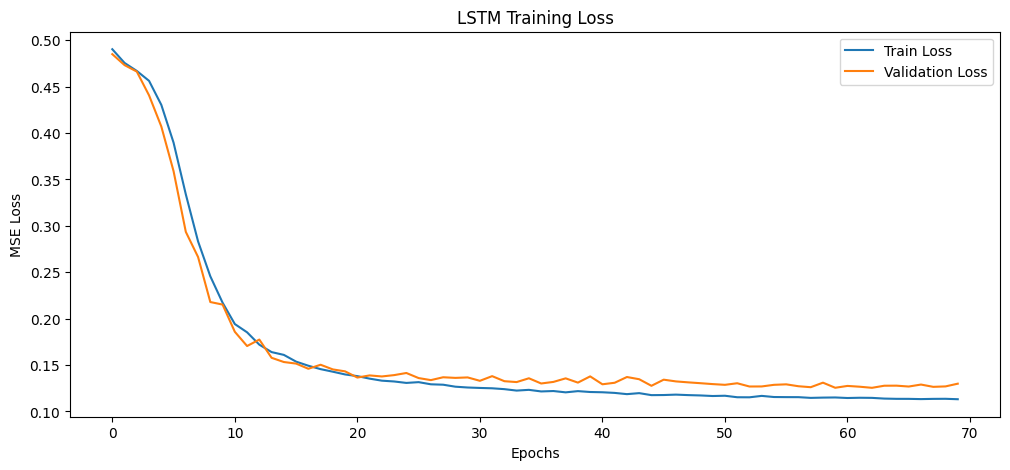

In [ ]:
#Plot Training History (Optimized Graphs)
plt.figure(figsize=(12,5))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('LSTM Training Loss')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.legend()
plt.show()

195/195 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step


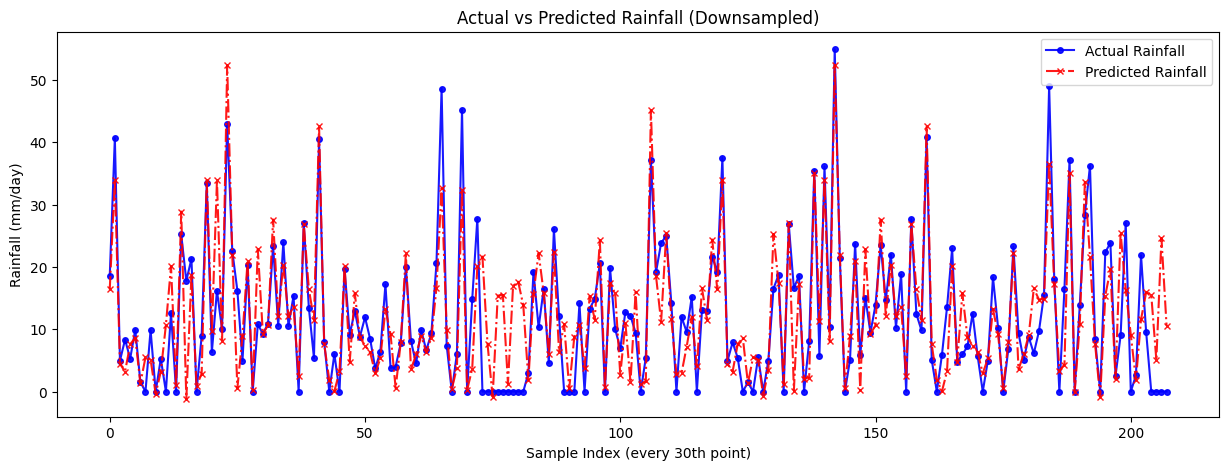

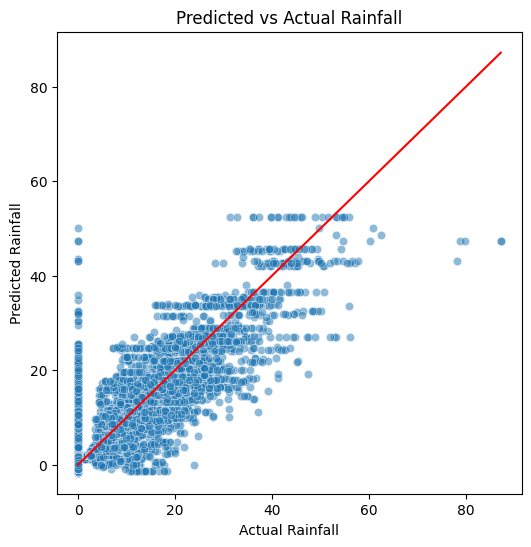

In [ ]:
#Make Predictions & Inverse Transform
y_pred = model1.predict(X1_test)

# Inverse scale to actual rainfall
y_test_inv = target_scaler1.inverse_transform(y1_test.reshape(-1,1))
y_pred_inv = target_scaler1.inverse_transform(y_pred)

# Time series plot
step = 30
plt.figure(figsize=(15,5))
plt.plot(y_test_inv[::step], label='Actual Rainfall', color='blue', marker='o', markersize=4, linestyle='-', alpha=0.9)
plt.plot(y_pred_inv[::step], label='Predicted Rainfall', color='red', marker='x', markersize=4, linestyle='-.', alpha=0.9)
plt.title('Actual vs Predicted Rainfall (Downsampled)')
plt.xlabel('Sample Index (every 30th point)')
plt.ylabel('Rainfall (mm/day)')
plt.legend()
plt.show()

# Scatter plot
plt.figure(figsize=(6,6))
sns.scatterplot(x=y_test_inv.flatten(), y=y_pred_inv.flatten(), alpha=0.5)
max_val = max(y_test_inv.flatten())
plt.plot([0, max_val], [0, max_val], color='red')
plt.title('Predicted vs Actual Rainfall')
plt.xlabel('Actual Rainfall')
plt.ylabel('Predicted Rainfall')
plt.show()


In [ ]:
#Correlation between Actual & Predicted Rainfall
corr = np.corrcoef(
    y_test_inv.flatten(),
    y_pred_inv.flatten()
)[0, 1]

print(f"Correlation (Actual vs Predicted): {corr:.4f}")

Correlation (Actual vs Predicted): 0.8107


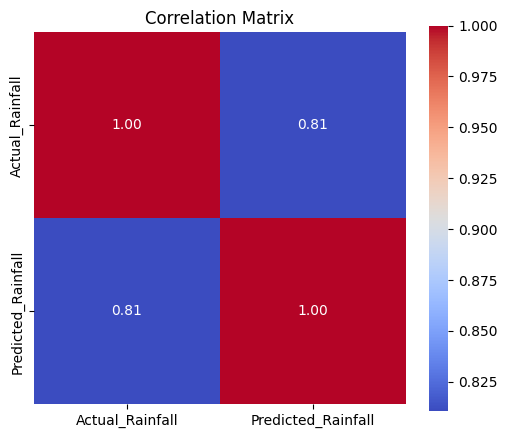

In [ ]:
#Full Correlation Matrix (Features + Rainfall)

corr_df = pd.DataFrame({
    'Actual_Rainfall': y_test_inv.flatten(),
    'Predicted_Rainfall': y_pred_inv.flatten()
})


plt.figure(figsize=(6,5))
sns.heatmap(
    corr_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    square=True
)
plt.title("Correlation Matrix")
plt.show()

In [ ]:
#MAE (Mean Absolute Error)
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(
    y_test_inv.flatten(),
    y_pred_inv.flatten()
)

print(f"MAE: {mae:.3f} mm/day")

#RMSE (Root Mean Squared Error)
from sklearn.metrics import mean_squared_error

rmse = np.sqrt(mean_squared_error(
    y_test_inv.flatten(),
    y_pred_inv.flatten()
))

print(f"RMSE: {rmse:.3f} mm/day")

MAE: 4.567 mm/day
RMSE: 6.733 mm/day


In [ ]:
#MODEL PERFORMANCE SUMMARY TABLE (Recommended)
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

r2 = r2_score(y_test_inv, y_pred_inv)
mae = mean_absolute_error(y_test_inv, y_pred_inv)
rmse = np.sqrt(mean_squared_error(y_test_inv, y_pred_inv))

metrics_df = pd.DataFrame({
    'Metric': ['R²', 'MAE (mm)', 'RMSE (mm)'],
    'Value': [r2, mae, rmse]
})

metrics_df

,Metric,Value
0,R²,0.647145
1,MAE (mm),4.566789
2,RMSE (mm),6.732746


In [ ]:
#Compairing against Climatology
baseline = np.mean(y_test_inv)
ss = 1 - (
    mean_squared_error(y_test_inv, y_pred_inv) /
    mean_squared_error(y_test_inv, np.full_like(y_test_inv, baseline))
)

print(f"Skill Score vs Climatology: {ss:.3f}")

Skill Score vs Climatology: 0.647


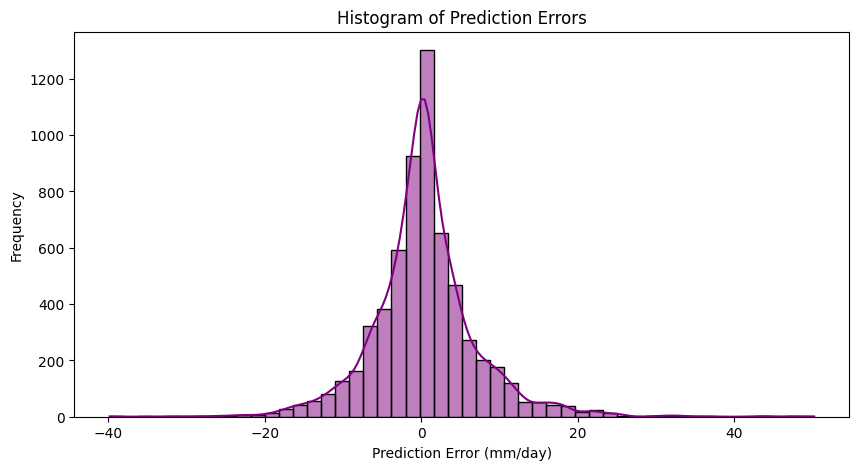

In [ ]:
#Histogram of prediction errors
errors = y_pred_inv.flatten() - y_test_inv.flatten()
plt.figure(figsize=(10,5))
sns.histplot(errors, bins=50, kde=True, color='purple')
plt.title('Histogram of Prediction Errors')
plt.xlabel('Prediction Error (mm/day)')
plt.ylabel('Frequency')
plt.show()

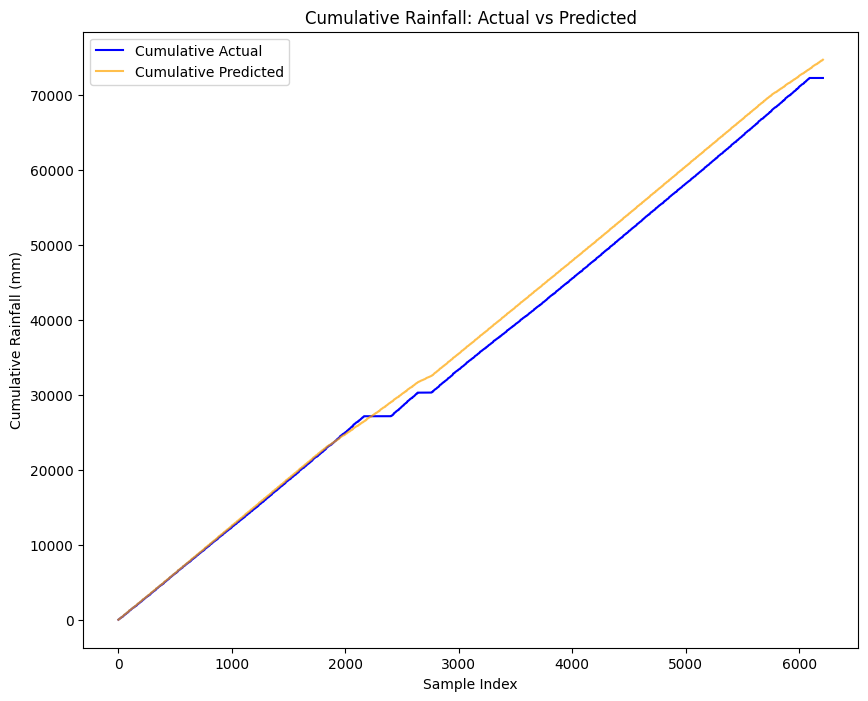

In [ ]:
#Cumulative rainfall comparison

plt.figure(figsize=(10,8))
plt.plot(np.cumsum(y_test_inv), label='Cumulative Actual', color='blue')
plt.plot(np.cumsum(y_pred_inv), label='Cumulative Predicted', color='orange', alpha=0.7)
plt.title('Cumulative Rainfall: Actual vs Predicted')
plt.xlabel('Sample Index')
plt.ylabel('Cumulative Rainfall (mm)')
plt.legend()
plt.show()

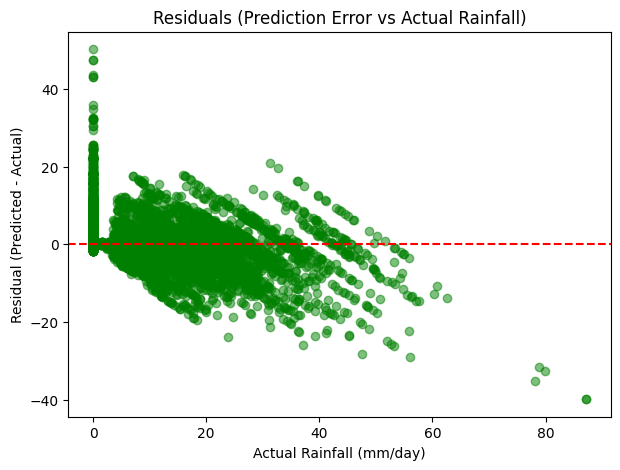

In [ ]:
#Residual plot

plt.figure(figsize=(7,5))
plt.scatter(y_test_inv.flatten(), errors, alpha=0.5, color='green')
plt.axhline(0, color='red', linestyle='--')
plt.title('Residuals (Prediction Error vs Actual Rainfall)')
plt.xlabel('Actual Rainfall (mm/day)')
plt.ylabel('Residual (Predicted - Actual)')
plt.show()

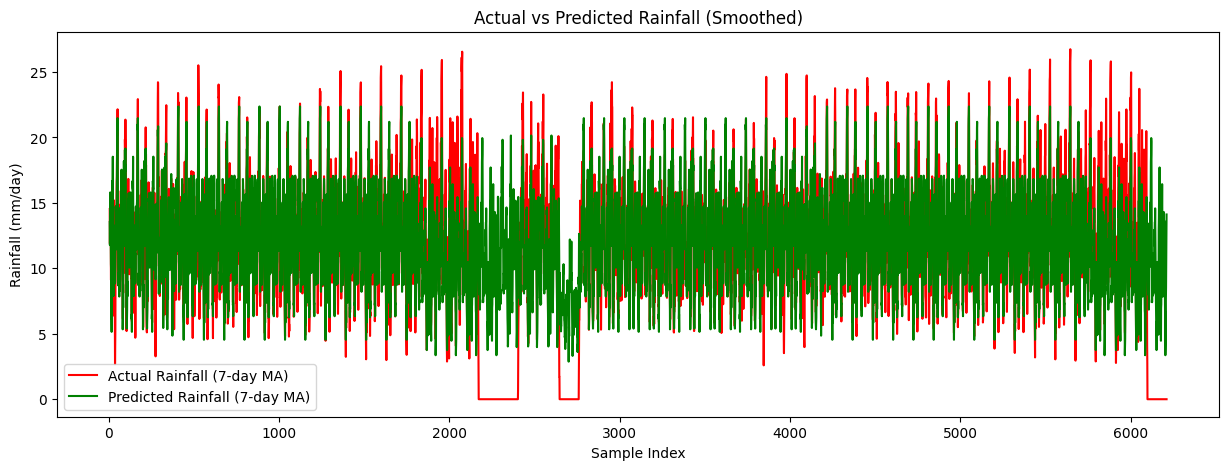

In [ ]:
#Smoothed time series (rolling average)
window = 7  #7-day rolling average
y_test_smooth = pd.Series(y_test_inv.flatten()).rolling(window).mean()
y_pred_smooth = pd.Series(y_pred_inv.flatten()).rolling(window).mean()

plt.figure(figsize=(15,5))
plt.plot(y_test_smooth, label='Actual Rainfall (7-day MA)', color='red')
plt.plot(y_pred_smooth, label='Predicted Rainfall (7-day MA)', color='green')
plt.title('Actual vs Predicted Rainfall (Smoothed)')
plt.xlabel('Sample Index')
plt.ylabel('Rainfall (mm/day)')
plt.legend()
plt.show()

In [ ]:
# ==============================
# 1. Install & import libraries
# ==============================
!pip install plotly

import pandas as pd
import numpy as np
import plotly.graph_objects as go

# ==============================
# 2. Prepare time series dataframe
# ==============================
# Align dates with test predictions
dates_test = merged1['date'].iloc[
    sequence_length + len(y1_train) :
    sequence_length + len(y1_train) + len(y_test_inv)
].reset_index(drop=True)

ts_df = pd.DataFrame({
    'date': dates_test,
    'Actual_Rainfall': y_test_inv.flatten(),
    'Predicted_Rainfall': y_pred_inv.flatten()
})

# Sort by time (important!)
ts_df = ts_df.sort_values('date')

# ==============================
# 3. Optional smoothing (recommended)
# ==============================
window = 7  # 7-day moving average
ts_df['Actual_MA'] = ts_df['Actual_Rainfall'].rolling(window).mean()
ts_df['Predicted_MA'] = ts_df['Predicted_Rainfall'].rolling(window).mean()

# ==============================
# 4. Dynamic interactive plot
# ==============================
fig = go.Figure()

# Actual rainfall
fig.add_trace(go.Scatter(
    x=ts_df['date'],
    y=ts_df['Actual_Rainfall'],
    mode='lines',
    name='Actual Rainfall',
    line=dict(width=1, color='blue'),
    opacity=0.4
))

# Predicted rainfall
fig.add_trace(go.Scatter(
    x=ts_df['date'],
    y=ts_df['Predicted_Rainfall'],
    mode='lines',
    name='Predicted Rainfall',
    line=dict(width=1, color='orange'),
    opacity=0.4
))

# Smoothed actual
fig.add_trace(go.Scatter(
    x=ts_df['date'],
    y=ts_df['Actual_MA'],
    mode='lines',
    name='Actual (7-day MA)',
    line=dict(width=3, color='blue')
))

# Smoothed predicted
fig.add_trace(go.Scatter(
    x=ts_df['date'],
    y=ts_df['Predicted_MA'],
    mode='lines',
    name='Predicted (7-day MA)',
    line=dict(width=3, dash='dash', color='orange')
))

# ==============================
# 5. Layout (clean & professional)
# ==============================
fig.update_layout(
    title='Dynamic Rainfall Time Series: Actual vs Predicted',
    xaxis_title='Date',
    yaxis_title='Rainfall (mm/day)',
    hovermode='x unified',
    template='plotly_white',
    legend=dict(
        orientation='h',
        yanchor='bottom',
        y=1.02,
        xanchor='right',
        x=1
    )
)

fig.show()
